In [34]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
import pandas as pd
intakes = pd.read_csv("ultra_clean_intakes_v2.csv")
household = pd.read_csv("ultra_clean_household_members_v2.csv")

# Abstract

In this part of the SLCM group project we analyzed the columns of our provided datasets to trim columns with redundant, useless, or PII information inside of them. We also isolated initial contact tickets from their subtickets to attempt to learn overarching facts about these people. There was a wealth of data for this related to the reconnect stage, but no data covering the rebuild or rethink stages. Additionally we had a question during analysis on if there were trends among people that created multiple first contact/newn profile tickets, however there were too few of these to make drawing any strong conclusions viable.

# 5 Questions

## \#1  
**Housing crisis severity: what share of tickets show active eviction risk (currently being evicted, or unhoused) versus stable housing? Does this differ by zip code or by household size?**

Out of 426 profile tickets 120 of them show urgent risk (being evicted or unhoused), which means the remaining 306 profile tickets are currently stable.  
When inspecting by zip code, 40214 and 40215 have significantly more stable than at risk profile tickets, however the amount of at risk profile tickets in those zipcodes exceed that of the count in any other zip codes. So it is likely that those are just more populated zip codes.  
When inspecting by household size we again see that the most popular family sized have both more stable and at risk profile tickets than less popular family sizes, and roughly all proportional to each other, no sharp change in proportion from family size to size, therefore likely no correlation we can observe from the data. Stable is alawys larger than at risk regardless of family size.

In [37]:
# pulls out new profiles only
profile_types = ['New Profile', 'Connected Neighbor Profile', 'Flourishing Neighbor Profile']
first_contact_intakes = intakes[intakes['Issue Type'].isin(profile_types)]

In [38]:
# pulls out the at risk rows
evicted_or_unhoused = first_contact_intakes[
    (first_contact_intakes['Custom field (Eviction Status)'] == 'Currently being evicted') |
    (first_contact_intakes['Custom field (Housing Status)'] == 'Unhoused')
]
print(len(evicted_or_unhoused))
# count of stable
stable = first_contact_intakes.drop(evicted_or_unhoused.index)
print(len(stable))

120
306


In [39]:
# Clean zip codes: keep only the first 5 digits and make sure they are numeric
zip_col = [c for c in first_contact_intakes.columns if 'zip' in c.lower()][0] if any('zip' in c.lower() for c in first_contact_intakes.columns) else 'Custom field (City)'

def clean_zip(val):
    if pd.isna(val):
        return val
    val_str = str(val).strip()
    # Extract first 5 digits if possible
    import re
    match = re.match(r'^(\d{5})', val_str)
    if match:
        return match.group(1)
    return None

# Apply the cleaning to all dataframes in place
intakes[zip_col] = intakes[zip_col].apply(clean_zip)
first_contact_intakes = intakes[intakes['Issue Type'].isin(profile_types)].copy()
evicted_or_unhoused = first_contact_intakes[
    (first_contact_intakes['Custom field (Eviction Status)'] == 'Currently being evicted') |
    (first_contact_intakes['Custom field (Housing Status)'] == 'Unhoused')
].copy()
stable = first_contact_intakes.drop(evicted_or_unhoused.index).copy()

print("Zip codes successfully cleaned to 5 digits!")

Zip codes successfully cleaned to 5 digits!


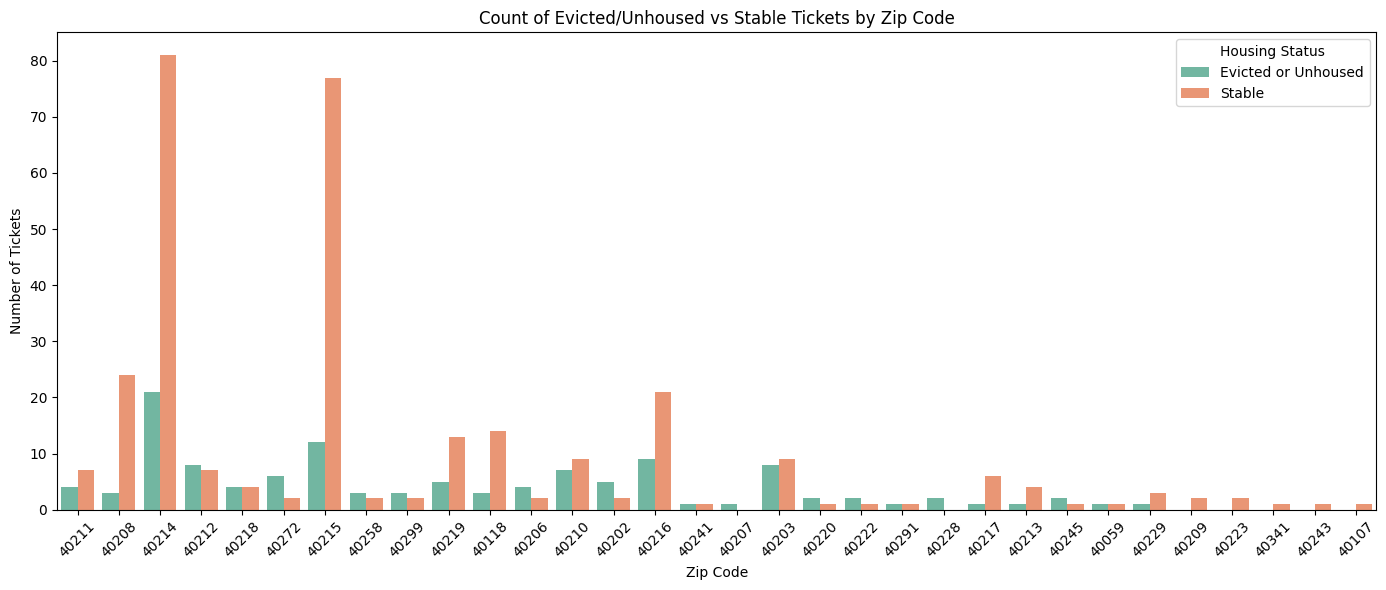

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Dynamic column identifier for zip code
zip_col = [c for c in first_contact_intakes.columns if 'zip' in c.lower()][0] if any('zip' in c.lower() for c in first_contact_intakes.columns) else 'Custom field (City)'

# Create a simplified DataFrame for plotting
ev_df = evicted_or_unhoused[[zip_col]].copy()
ev_df['Status'] = 'Evicted or Unhoused'

st_df = stable[[zip_col]].copy()
st_df['Status'] = 'Stable'

plot_df = pd.concat([ev_df, st_df], ignore_index=True)

# Draw the barplot
plt.figure(figsize=(14, 6))
sns.countplot(data=plot_df, x=zip_col, hue='Status', palette='Set2')
plt.title('Count of Evicted/Unhoused vs Stable Tickets by Zip Code')
plt.xlabel('Zip Code')
plt.ylabel('Number of Tickets')
plt.xticks(rotation=45)
plt.legend(title='Housing Status')
plt.tight_layout()
plt.show()

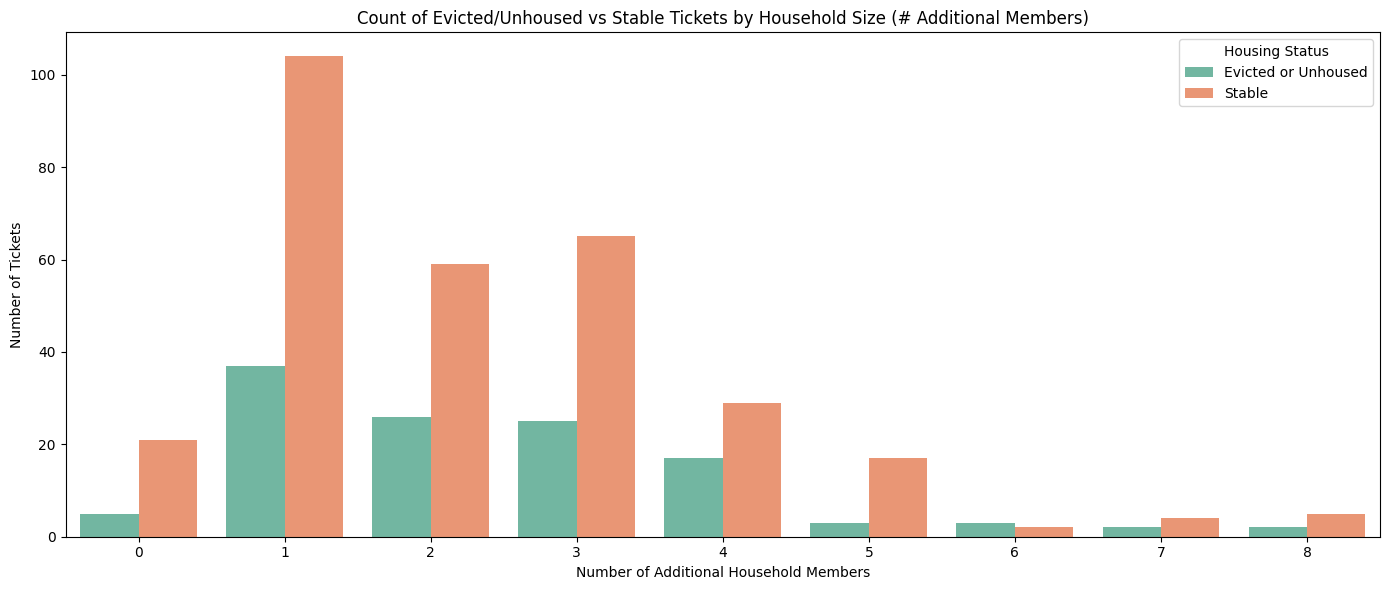

In [41]:
# Identify household size column
hh_col = '# Additional Household Members' if '# Additional Household Members' in first_contact_intakes.columns else None

if hh_col:
    # Create a simplified DataFrame for household size plotting
    ev_hh = evicted_or_unhoused[[hh_col]].copy()
    ev_hh['Status'] = 'Evicted or Unhoused'

    st_hh = stable[[hh_col]].copy()
    st_hh['Status'] = 'Stable'

    plot_hh_df = pd.concat([ev_hh, st_hh], ignore_index=True)

    # Draw the barplot
    plt.figure(figsize=(14, 6))
    sns.countplot(data=plot_hh_df, x=hh_col, hue='Status', palette='Set2')
    plt.title('Count of Evicted/Unhoused vs Stable Tickets by Household Size (# Additional Members)')
    plt.xlabel('Number of Additional Household Members')
    plt.ylabel('Number of Tickets')
    plt.legend(title='Housing Status')
    plt.tight_layout()
    plt.show()
else:
    print("Household size column not found in the dataset.")

## \#2
**Employment vs. income mismatch: employment status alone doesn't predict financial hardship in this data. Show, with a plot, how income amount and source of income vary between employed and unemployed households.**

As expected most employed people get their income from a full time salary and most unemployed people either have no income or rely on snap benefits for income. What is notable however is that the 2nd highest category of "no income" is fully employeed households, indicating that despite full time employment either they aren't getting paid enough to sustain themselves or there is some sort of extenuating circumstances causing their income to not currently keep up with their expenses.

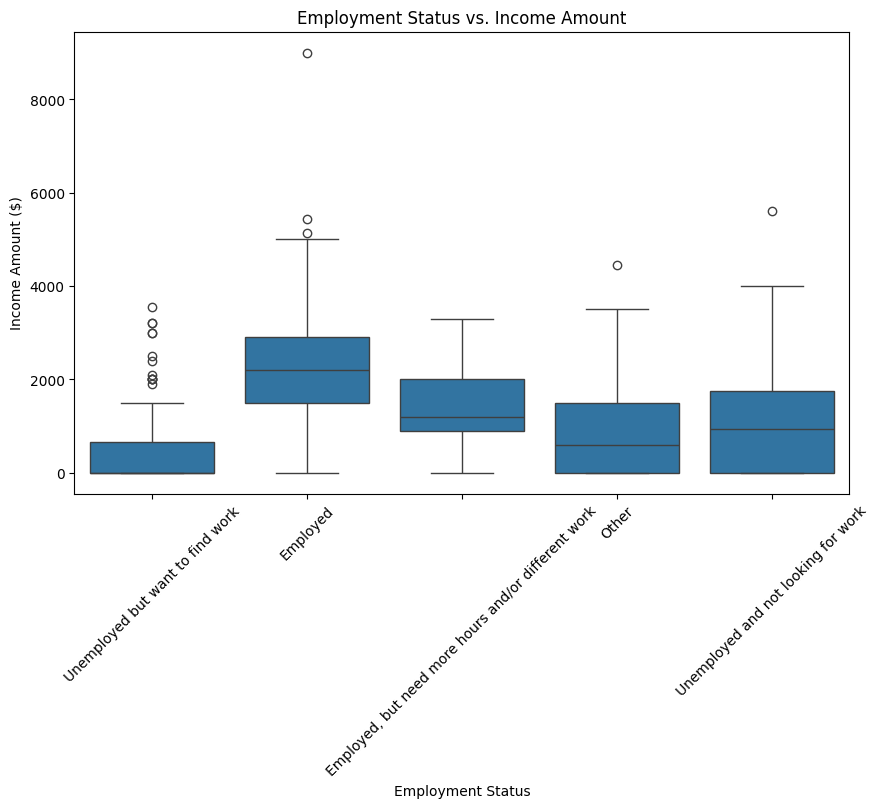

In [42]:
# plot income amount against employed/unemployed
plt.figure(figsize=(10, 6))
sns.boxplot(x='Custom field (Employment Status)', y='Custom field (Income Amount ($))', data=first_contact_intakes)
plt.title('Employment Status vs. Income Amount')
plt.xlabel('Employment Status')
plt.ylabel('Income Amount ($)')
# shrink text size
plt.xticks(rotation=45)
plt.show()

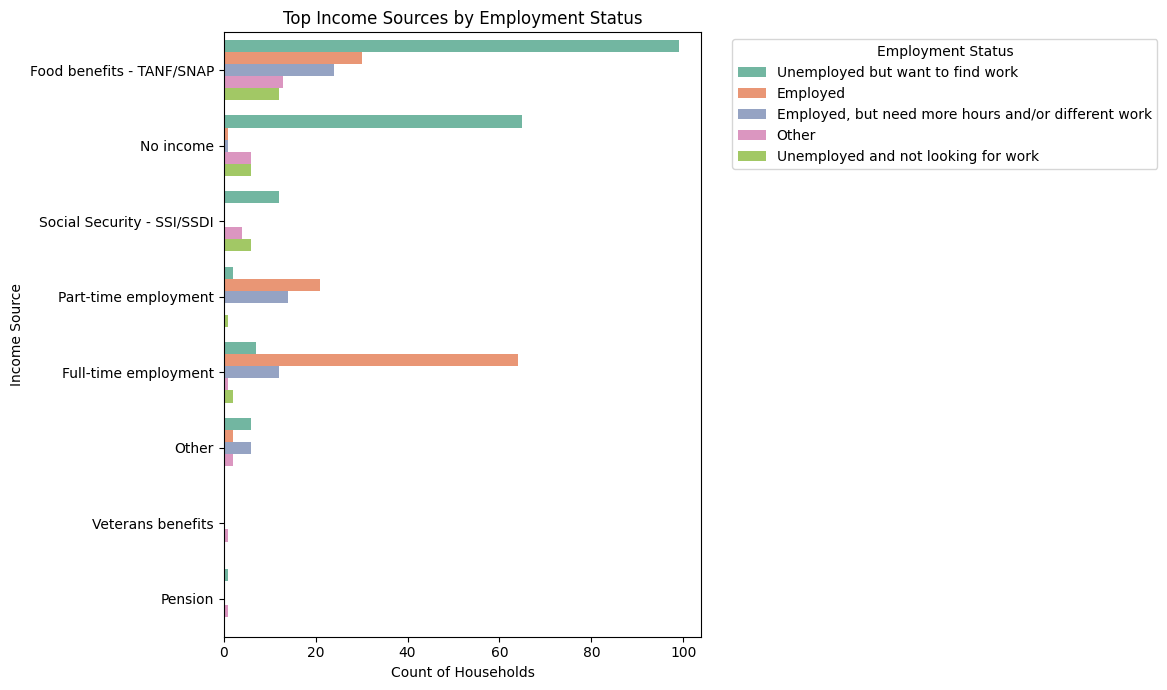

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filter the dataset for the top income sources directly using the column name string
top_sources = first_contact_intakes['Custom field (Source of income)'].value_counts().nlargest(8).index
filtered_df = first_contact_intakes[first_contact_intakes['Custom field (Source of income)'].isin(top_sources)]

plt.figure(figsize=(12, 7))
sns.countplot(
    y='Custom field (Source of income)',
    hue='Custom field (Employment Status)',
    data=filtered_df,
    palette='Set2'
)
plt.title('Top Income Sources by Employment Status')
plt.xlabel('Count of Households')
plt.ylabel('Income Source')
plt.legend(title='Employment Status', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## \#3  
**Household composition: what does the typical household look like in this data (household size, number of children, ages)? Use household_members_long_v2.csv to describe the additional family members, not just the primary contact.**

On average it looks like a household has ~2 kids and ~1.5 adults for an average of ~3.5 people per household.  
When inspecting the data for these household members in the hosuehold dataset we can see that reported ethnicities of white, black, and mixed make up well over 90% of family members, and when inspecting the ages we can see that the average age is below 10, with approximately 80% of age values lying below 17.

In [44]:
# sum the integer values in Custom field (People in Household 17 and Under)
print("Average kids in house", first_contact_intakes['Custom field (People in Household 17 and Under)'].sum()/ len(first_contact_intakes))
# sum the integer values in Custom field (People in Household 18+)
print("Average adults in house", first_contact_intakes['Custom field (People in Household 18+)'].sum()/ len(first_contact_intakes))
avg_family_members = (first_contact_intakes['Custom field (People in Household 17 and Under)'].sum() + first_contact_intakes['Custom field (People in Household 18+)'].sum()) / len(first_contact_intakes)
print("Average Family Members", avg_family_members)

Average kids in house 2.0821596244131455
Average adults in house 1.4366197183098592
Average Family Members 3.5187793427230045


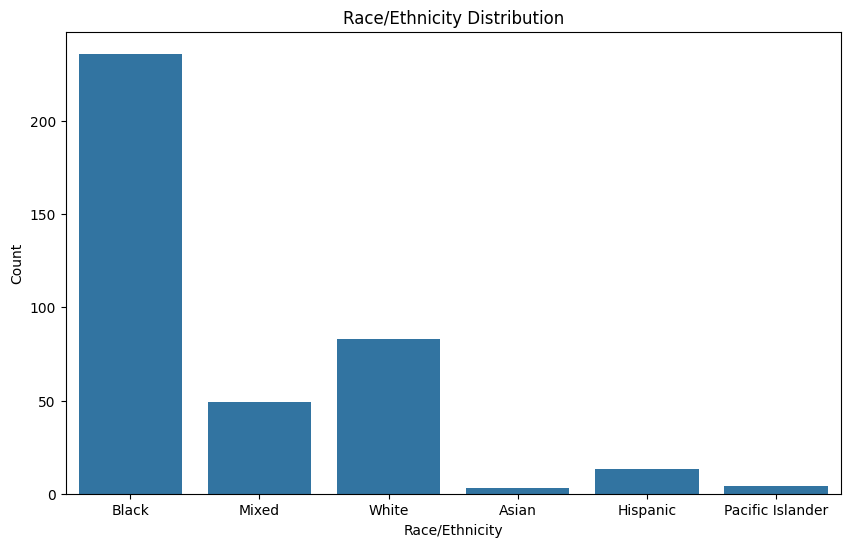

In [45]:
# use the clean_household data to plot race/ethnicity
plt.figure(figsize=(10, 6))
sns.countplot(x='Race/Ethnicity', data=household)
plt.title('Race/Ethnicity Distribution')
plt.xlabel('Race/Ethnicity')
plt.ylabel('Count')
plt.show()

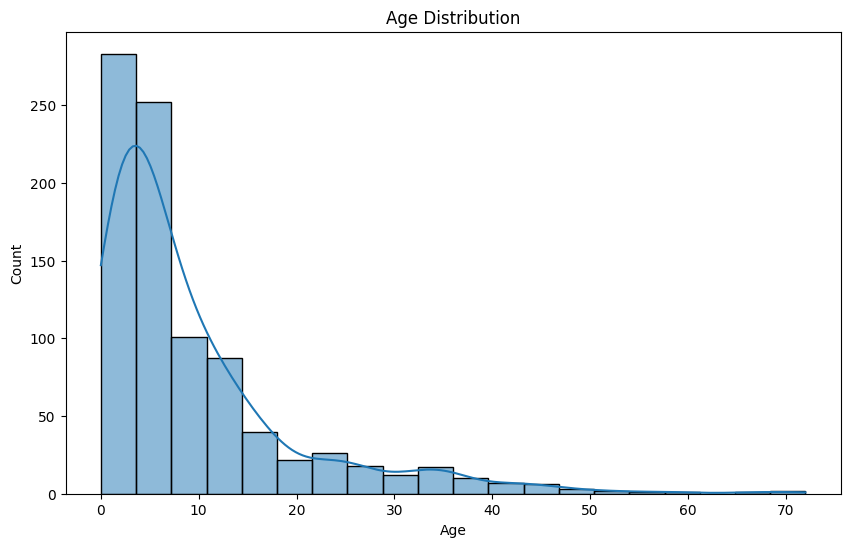

In [46]:
# plot the ages
plt.figure(figsize=(10, 6))
sns.histplot(household['Age'], bins=20, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

## \#4  
**Repeat contact: using PID, how many people appear on more than one ticket? For people with 2+ tickets, does anything change between their first and most recent ticket (housing status, eviction status)?**

When looking at how many repeat PID's appear as profile tickets when can see 27 repeat clients. When comparing and contrasting the housing status and eviction status between their previous ticket and other ticket, we can observe 5 changes in housing status and 8 changes in eviction status.

In [47]:
import pandas as pd

# Ensure Created is in datetime format
first_contact_intakes['Created'] = pd.to_datetime(first_contact_intakes['Created'])

# 1. Find people (PIDs) who appear on more than one ticket strictly within first_contact_intakes
ticket_counts = first_contact_intakes['PID'].dropna().value_counts()
multi_ticket_pids = ticket_counts[ticket_counts >= 2].index
print(f"Number of people appearing on more than one ticket in first_contact_intakes: {len(multi_ticket_pids)}")

# 2. Track changes between first and most recent ticket for these individuals
change_housing = 0
change_eviction = 0
total_analyzed = 0

for pid in multi_ticket_pids:
    # Get all tickets for this person from first_contact_intakes sorted by Created date
    person_tickets = first_contact_intakes[first_contact_intakes['PID'] == pid].sort_values('Created')

    if len(person_tickets) >= 2:
        first_ticket = person_tickets.iloc[0]
        last_ticket = person_tickets.iloc[-1]

        # Retrieve statuses
        first_housing = first_ticket.get('Custom field (Housing Status)')
        last_housing = last_ticket.get('Custom field (Housing Status)')

        first_eviction = first_ticket.get('Custom field (Eviction Status)')
        last_eviction = last_ticket.get('Custom field (Eviction Status)')

        # Compare housing status
        if pd.notna(first_housing) and pd.notna(last_housing) and first_housing != last_housing:
            change_housing += 1

        # Compare eviction status
        if pd.notna(first_eviction) and pd.notna(last_eviction) and first_eviction != last_eviction:
            change_eviction += 1

        total_analyzed += 1

print(f"\nOut of {total_analyzed} analyzed individuals with multiple tickets:")
print(f"- {change_housing} individuals changed their Housing Status.")
print(f"- {change_eviction} individuals changed their Eviction Status.")

Number of people appearing on more than one ticket in first_contact_intakes: 27

Out of 27 analyzed individuals with multiple tickets:
- 5 individuals changed their Housing Status.
- 8 individuals changed their Eviction Status.


/tmp/ipykernel_2218/2633404293.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  first_contact_intakes['Created'] = pd.to_datetime(first_contact_intakes['Created'])


## \#5  
**Data quality: find and document at least two data quality issues in this dataset. Explain how you would handle each one and why.**

One data quality issue is that the column namning scheme is not consistent, since the dataset is not prohibatively large I would recommend migrating the data to a new database with a consistent naming scheme and putting new data there.  

Another data quality issue is that things like race and city columns needed name cleaning. To fix this the intake form could simply have a dropdown instead of allowing custom input.

# What did you get to know?


What surprised me about this data is that only 27 people created multiple tickets with SLCM, which leads me to believe that the people who are contacting them usually are about to get the assistance that they need either directly through SLCM or through bring referred to another more applicable program.


We've learned that most of the households in need of assistance have 3-4 members, and often the other family members are very young, 10 or below. This surprised me but also makes sense as it aligns with the SLCM goal of helping mothers with childrens aged 0-5.  
It was also surprised to learn that there were a significant amount of employed first contact tickets that were not making enough money from a full time salary to sustain themselves and relied on other income soruces such as snap benefits to cover their expenses.
Finally, I was also surprised to see that people that were working but wanted more hours had approximately the same median salary as those that were unemployed and *not* looking for work. I don't want to assume any conclusions from that but I thought the observation was an interesting one nonetheless.


One question we would not be able to answer with this data alone is what happens after the reconnect assistance, in the rebuild and rethink stages. There appears to be no fields that directly track whether or not a client is connected to a longer term assistance or policy change program after getting the short term help they needed.